Using device: mps
Checking ground truth directory: /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/results/pseudo_ground_truth
Found 100 mask files in GT directory.
Initializing DeepLabV3 with ResNet-50 backbone...

EVALUATING MODEL: DeepLabV3

--- Quantitative Results: DeepLabV3 ---
* Valid Samples Evaluated : 100
* Model Parameters        : 42.00 M
* Avg Latency             : 256.65 ms
* Median Latency          : 252.00 ms
* Average FPS             : 3.90
* Pixel Accuracy          : 34.26%
* Mean IoU (mIoU)         : 1.91%
----------------------------------------------


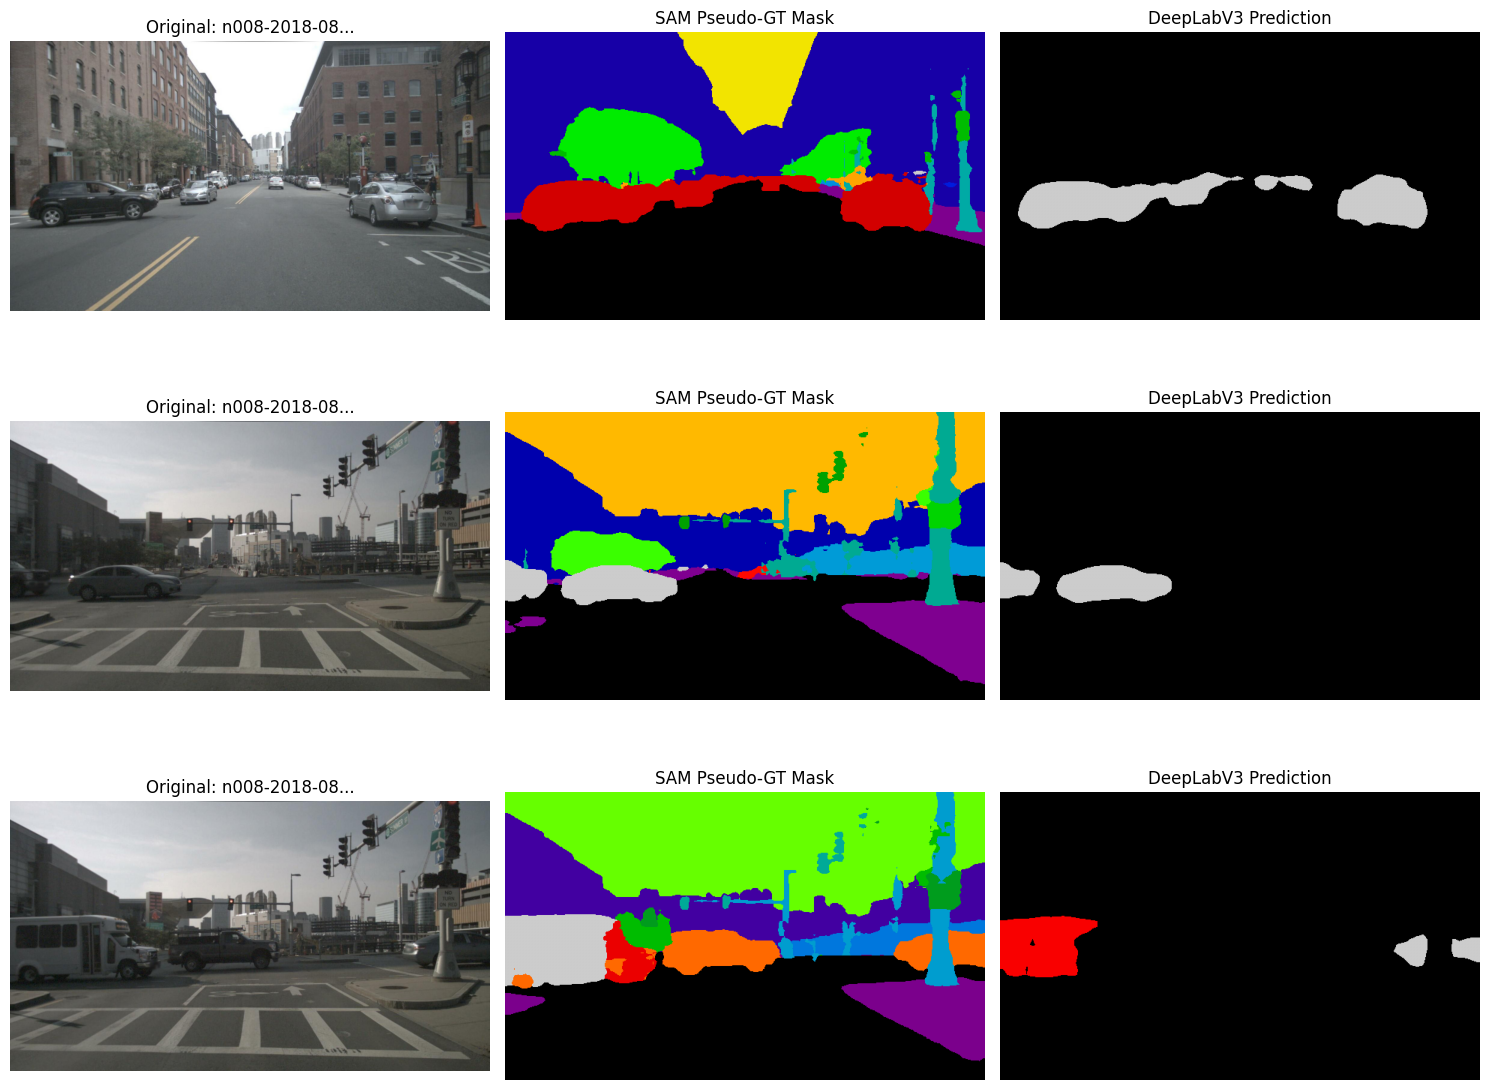

In [12]:
import time
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision.models.segmentation as models
from torchvision.models.segmentation import DeepLabV3_ResNet50_Weights
import torchvision.transforms as T

# 0. Define Required Paths & Device Setup (Updated Ground Truth Path)
cam_front_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/v1.0-mini/samples/CAM_FRONT/")
benchmark_images = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
gt_output_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/results/pseudo_ground_truth")

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Checking ground truth directory: {gt_output_dir}")
print(f"Found {len(list(gt_output_dir.glob('*.png')))} mask files in GT directory.")

# Define standard transforms
input_size = (384, 640)
transform = T.Compose([
    T.Resize(input_size),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# 1. Initialize DeepLabV3 with default COCO/VOC pretrained weights
print("Initializing DeepLabV3 with ResNet-50 backbone...")
deeplab_model = models.deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)

# 2. Wrapper to extract the semantic segmentation output tensor safely
class DeepLabV3Wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        return self.model(x)['out']

deeplab_wrapped = DeepLabV3Wrapper(deeplab_model)

# 3. Comprehensive Evaluation & Visualization Function
def evaluate_and_visualize_model(
    model_name, 
    model, 
    image_paths, 
    gt_dir, 
    transform, 
    device, 
    num_classes=19, 
    input_size=(384, 640)
):
    model.eval()
    model.to(device)

    total_params = sum(p.numel() for p in model.parameters()) / 1e6
    latencies = []
    confusion_matrix = np.zeros((num_classes, num_classes))
    valid_samples = []

    print(f"\n==============================================")
    print(f"EVALUATING MODEL: {model_name}")
    print(f"==============================================")

    with torch.no_grad():
        dummy = torch.randn(1, 3, input_size[0], input_size[1]).to(device)
        _ = model(dummy)

        for img_path in image_paths:
            mask_path = gt_dir / f"{img_path.stem}_mask.png"
            if not mask_path.exists():
                continue
            
            image = Image.open(img_path).convert("RGB")
            gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
            
            tensor = transform(image).unsqueeze(0).to(device)

            start_time = time.time()
            output = model(tensor)
            
            if device.type == "mps":
                torch.mps.synchronize()
            elif device.type == "cuda":
                torch.cuda.synchronize()
                
            elapsed = time.time() - start_time
            latencies.append(elapsed)

            pred = output.argmax(dim=1).cpu().numpy().squeeze()

            if pred.shape != gt_mask.shape:
                gt_mask = np.array(
                    Image.fromarray(gt_mask.astype(np.uint8)).resize(
                        (pred.shape[1], pred.shape[0]), Image.NEAREST
                    )
                )

            mask = (gt_mask >= 0) & (gt_mask < num_classes)
            confusion_matrix += np.bincount(
                num_classes * gt_mask[mask].astype(int) + pred[mask].astype(int),
                minlength=num_classes ** 2,
            ).reshape(num_classes, num_classes)

            valid_samples.append((img_path, gt_mask, pred))

    if not latencies:
        print("[Error] No matching ground truth masks found for the benchmark images. Please check file name formatting.")
        return None

    avg_lat = np.array(latencies).mean()
    med_lat = np.median(np.array(latencies))
    avg_fps = 1.0 / avg_lat

    intersection = np.diag(confusion_matrix)
    union = confusion_matrix.sum(axis=1) + confusion_matrix.sum(axis=0) - intersection
    per_class_iou = np.divide(
        intersection, union, out=np.zeros_like(intersection, dtype=float), where=union != 0
    )
    mIoU = np.nanmean(per_class_iou)

    total_correct = np.sum(intersection)
    total_pixels = np.sum(confusion_matrix)
    pixel_accuracy = (total_correct / total_pixels) if total_pixels > 0 else 0.0

    print(f"\n--- Quantitative Results: {model_name} ---")
    print(f"* Valid Samples Evaluated : {len(valid_samples)}")
    print(f"* Model Parameters        : {total_params:.2f} M")
    print(f"* Avg Latency             : {avg_lat * 1000:.2f} ms")
    print(f"* Median Latency          : {med_lat * 1000:.2f} ms")
    print(f"* Average FPS             : {avg_fps:.2f}")
    print(f"* Pixel Accuracy          : {pixel_accuracy * 100:.2f}%")
    print(f"* Mean IoU (mIoU)         : {mIoU * 100:.2f}%")
    print(f"----------------------------------------------")

    if valid_samples:
        viz_samples = random.sample(valid_samples, min(3, len(valid_samples)))
        fig, axes = plt.subplots(len(viz_samples), 3, figsize=(15, 4 * len(viz_samples)))
        
        if len(viz_samples) == 1:
            axes = np.expand_dims(axes, 0)

        for idx, (img_p, gt, pred) in enumerate(viz_samples):
            orig_img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)

            axes[idx, 0].imshow(orig_img)
            axes[idx, 0].set_title(f"Original: {img_p.name[:12]}...")
            axes[idx, 0].axis("off")

            axes[idx, 1].imshow(gt, cmap="nipy_spectral")
            axes[idx, 1].set_title("SAM Pseudo-GT Mask")
            axes[idx, 1].axis("off")

            axes[idx, 2].imshow(pred, cmap="nipy_spectral")
            axes[idx, 2].set_title(f"{model_name} Prediction")
            axes[idx, 2].axis("off")

        plt.tight_layout()
        plt.show()

    return {
        "Model": model_name,
        "Params (M)": round(total_params, 2),
        "Avg Latency (ms)": round(avg_lat * 1000, 2),
        "FPS": round(avg_fps, 2),
        "Pixel Acc (%)": round(pixel_accuracy * 100, 2),
        "mIoU (%)": round(mIoU * 100, 2)
    }

# 4. Execute Pipeline for DeepLabV3
deeplab_metrics = evaluate_and_visualize_model(
    model_name="DeepLabV3",
    model=deeplab_wrapped,
    image_paths=benchmark_images,
    gt_dir=gt_output_dir,
    transform=transform,
    device=device
)